# E2 - Architecture Comparison: ResNet-18 vs ResNet-34

**Purpose:** Train ResNet-34 under the same conditions as E1 and compare against the E1 ResNet-18 baseline.

This notebook is the ResNet-34 version of `Dan_E2_training_local.ipynb`.

Primary outputs:

- `outputs/dan/training/best_resnet34_E2.pth`
- `outputs/dan/training/resnet34_E2_topk.json`
- `outputs/dan/training/E2_architecture_comparison_resnet18_vs_resnet34.csv`
- `outputs/dan/training/E2_topk_comparison_resnet18_vs_resnet34.png`
- `outputs/dan/training/E2_topk_separation_resnet34.json`
- `outputs/dan/experiment_results.csv`

Note: `EXPERIMENT_ID` is set to `E2` so E3 can select the best E1/E2 model.
If you already have a ResNet-50 E2 row in the registry, this notebook adds/updates a separate row where `model = resnet34`.


In [1]:
import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchvision.models import resnet34, ResNet34_Weights

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score
)


In [2]:
def get_device():
    if torch.backends.mps.is_available():
        return torch.device('mps')
    if torch.cuda.is_available():
        return torch.device('cuda')
    return torch.device('cpu')

DEVICE = get_device()
USE_AMP = DEVICE.type == 'cuda'
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

BASE_DIR = Path('.').resolve()
DATA_DIR = BASE_DIR / 'data'
CLEAN_ROOT = DATA_DIR / 'clean_tree'
TRAIN_DIR = CLEAN_ROOT / 'train'
VAL_DIR = CLEAN_ROOT / 'val'
TEST_DIR = CLEAN_ROOT / 'test'

DAN_OUTPUTS_DIR = BASE_DIR / 'outputs' / 'dan'
OUTPUT_DIR = DAN_OUTPUTS_DIR / 'training'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BASELINE_OUTPUT_DIR = DAN_OUTPUTS_DIR / 'training_baseline'
RESULTS_PATH = DAN_OUTPUTS_DIR / 'experiment_results.csv'
E1_TOPK_PATH = BASELINE_OUTPUT_DIR / 'resnet18_E1_topk.json'

EXPECTED_NUM_CLASSES = 23
BATCH_SIZE = 32
NUM_WORKERS = 0
PIN_MEMORY = DEVICE.type == 'cuda'

EXPERIMENT_ID = 'E2'
MODEL_NAME = 'resnet34'

HEAD_EPOCHS = 3
FINETUNE_EPOCHS = 20
HEAD_LR = 1e-3
BACKBONE_LR = 1e-4
WEIGHT_DECAY = 1e-4
LR_FACTOR = 0.5
LR_PATIENCE = 3
EARLY_STOPPING_PATIENCE = 5

CKPT_PATH = OUTPUT_DIR / f'best_{MODEL_NAME}_{EXPERIMENT_ID}.pth'
CONFIG_PATH = OUTPUT_DIR / f'{MODEL_NAME}_{EXPERIMENT_ID}_config.json'
HISTORY_PATH = OUTPUT_DIR / f'{MODEL_NAME}_{EXPERIMENT_ID}_history.csv'
LEARNING_CURVES_PATH = OUTPUT_DIR / f'{MODEL_NAME}_{EXPERIMENT_ID}_learning_curves.png'
TOPK_PATH = OUTPUT_DIR / f'{MODEL_NAME}_{EXPERIMENT_ID}_topk.json'
COMPARISON_PATH = OUTPUT_DIR / f'{EXPERIMENT_ID}_architecture_comparison_resnet18_vs_{MODEL_NAME}.csv'
TOPK_PLOT_PATH = OUTPUT_DIR / f'{EXPERIMENT_ID}_topk_comparison_resnet18_vs_{MODEL_NAME}.png'
SEPARATION_PATH = OUTPUT_DIR / f'{EXPERIMENT_ID}_topk_separation_{MODEL_NAME}.json'
CONFUSION_PNG_PATH = OUTPUT_DIR / f'{MODEL_NAME}_{EXPERIMENT_ID}_confusion_matrix.png'
CONFUSION_CSV_PATH = OUTPUT_DIR / f'{MODEL_NAME}_{EXPERIMENT_ID}_confusion_matrix.csv'
PERCLASS_CSV_PATH = OUTPUT_DIR / f'{MODEL_NAME}_{EXPERIMENT_ID}_per_class.csv'
REPORT_PATH = OUTPUT_DIR / f'{MODEL_NAME}_{EXPERIMENT_ID}_report.txt'

assert TRAIN_DIR.exists(), f'Missing {TRAIN_DIR}. Run Dan_preprocessing_local.ipynb first.'
assert VAL_DIR.exists(), f'Missing {VAL_DIR}.'
assert TEST_DIR.exists(), f'Missing {TEST_DIR}.'

print('Experiment:', EXPERIMENT_ID)
print('Model:', MODEL_NAME)
print('Device:', DEVICE)
print('Train dir:', TRAIN_DIR)
print('Val dir :', VAL_DIR)
print('Test dir :', TEST_DIR)
print('Outputs :', OUTPUT_DIR)
print('Registry :', RESULTS_PATH)


Experiment: E2
Model: resnet34
Device: mps
Train dir: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/data/clean_tree/train
Val dir : /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/data/clean_tree/val
Test dir : /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/data/clean_tree/test
Outputs : /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training
Registry : /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/experiment_results.csv


In [3]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

def _to_rgb(img):
    return img.convert('RGB')

train_transform = transforms.Compose([
    transforms.Lambda(_to_rgb),
    transforms.RandomResizedCrop(size=224, scale=(0.80, 1.00), ratio=(0.90, 1.10)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Lambda(_to_rgb),
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

train_dataset = ImageFolder(root=str(TRAIN_DIR), transform=train_transform)
val_dataset = ImageFolder(root=str(VAL_DIR), transform=eval_transform)
test_dataset = ImageFolder(root=str(TEST_DIR), transform=eval_transform)

print('Dataset sizes:')
print('Train:', len(train_dataset))
print('Val :', len(val_dataset))
print('Test :', len(test_dataset))

assert len(train_dataset.classes) == EXPECTED_NUM_CLASSES
assert train_dataset.class_to_idx == val_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx

class_names = train_dataset.classes

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

print('Classes:', len(class_names))
print('Batches - train:', len(train_loader), '| val:', len(val_loader), '| test:', len(test_loader))


Dataset sizes:
Train: 3850
Val : 401
Test : 405
Classes: 23
Batches - train: 121 | val: 13 | test: 13


In [4]:
def build_model(num_classes, device):
    weights = ResNet34_Weights.IMAGENET1K_V1
    model = resnet34(weights=weights)

    for param in model.parameters():
        param.requires_grad = False

    in_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Dropout(p=0.2),
        nn.Linear(in_features, num_classes)
    )
    return model.to(device)

model = build_model(EXPECTED_NUM_CLASSES, DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print('Architecture: ResNet-34')
print('Feature dim:', model.fc[1].in_features)
print(f'Total params: {total_params:,}')
print(f'Trainable params: {trainable_params:,} (head only)')

criterion = nn.CrossEntropyLoss()
head_optimizer = optim.AdamW(model.fc.parameters(), lr=HEAD_LR, weight_decay=WEIGHT_DECAY)

if USE_AMP:
    scaler = torch.cuda.amp.GradScaler()
else:
    scaler = None


Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /Users/dandev947366/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100.0%


Architecture: ResNet-34
Feature dim: 512
Total params: 21,296,471
Trainable params: 11,799 (head only)


In [5]:
def set_backbone_batchnorm_eval(model):
    for module in model.modules():
        if isinstance(module, (nn.BatchNorm1d, nn.BatchNorm2d, nn.BatchNorm3d)):
            module.eval()

def calculate_metrics(labels, predictions):
    return {
        'accuracy': accuracy_score(labels, predictions),
        'precision_macro': precision_score(labels, predictions, average='macro', zero_division=0),
        'recall_macro': recall_score(labels, predictions, average='macro', zero_division=0),
        'f1_macro': f1_score(labels, predictions, average='macro', zero_division=0),
        'f1_weighted': f1_score(labels, predictions, average='weighted', zero_division=0),
        'balanced_accuracy': balanced_accuracy_score(labels, predictions)
    }

def train_one_epoch(model, loader, criterion, optimizer, scaler, device, use_amp, head_warmup=False):
    model.train()
    if head_warmup:
        set_backbone_batchnorm_eval(model)

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        if use_amp:
            with torch.autocast(device_type='cuda'):
                outputs = model(images)
                loss = criterion(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

        running_loss += loss.item() * labels.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device, use_amp):
    model.eval()
    running_loss = 0.0
    total = 0
    all_preds = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if use_amp:
            with torch.autocast(device_type='cuda'):
                outputs = model(images)
                loss = criterion(outputs, labels)
        else:
            outputs = model(images)
            loss = criterion(outputs, labels)

        running_loss += loss.item() * labels.size(0)
        preds = outputs.argmax(dim=1)
        all_preds.append(preds.cpu())
        all_labels.append(labels.cpu())
        total += labels.size(0)

    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()

    metrics = calculate_metrics(all_labels, all_preds)
    metrics['loss'] = running_loss / total
    metrics['predictions'] = all_preds
    metrics['labels'] = all_labels
    return metrics

@torch.no_grad()
def compute_topk(model, loader, device, use_amp, k_values):
    model.eval()
    max_k = min(max(k_values), EXPECTED_NUM_CLASSES)
    top_k_correct = {k: 0 for k in k_values}
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if use_amp:
            with torch.autocast(device_type='cuda'):
                outputs = model(images)
        else:
            outputs = model(images)

        top_k_preds = outputs.topk(k=max_k, dim=1).indices
        total += labels.size(0)

        for k in k_values:
            correct = (top_k_preds[:, :k] == labels.unsqueeze(1)).any(dim=1).sum().item()
            top_k_correct[k] += correct

    return {k: top_k_correct[k] / total for k in k_values}

def save_checkpoint(model, optimizer, epoch, stage, metrics):
    payload = {
        'experiment': EXPERIMENT_ID,
        'model': MODEL_NAME,
        'epoch': epoch,
        'stage': stage,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'classes': class_names,
        'val_loss': metrics['loss'],
        'val_accuracy': metrics['accuracy'],
        'val_precision_macro': metrics['precision_macro'],
        'val_recall_macro': metrics['recall_macro'],
        'val_f1_macro': metrics['f1_macro'],
        'val_balanced_accuracy': metrics['balanced_accuracy']
    }
    torch.save(payload, CKPT_PATH)

def load_checkpoint(path, device):
    try:
        return torch.load(path, map_location=device, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=device)

print('Functions ready.')


Functions ready.


Stage 1: Head warmup
HEAD 1/3 | train_loss=2.8877 | train_acc=0.1538 | val_loss=2.4376 | val_acc=0.2893 | val_f1=0.2482
Checkpoint saved (head).
HEAD 2/3 | train_loss=2.4080 | train_acc=0.2966 | val_loss=2.1182 | val_acc=0.3965 | val_f1=0.4058
Checkpoint saved (head).
HEAD 3/3 | train_loss=2.1667 | train_acc=0.3735 | val_loss=1.9619 | val_acc=0.4364 | val_f1=0.4373
Checkpoint saved (head).
Stage 2: Full fine-tuning
FT 1/20 | train_loss=1.2524 | train_acc=0.6138 | val_loss=0.7629 | val_acc=0.7706 | val_f1=0.7754 | lr=1.00e-04
Checkpoint saved (fine-tune).
FT 2/20 | train_loss=0.4519 | train_acc=0.8605 | val_loss=0.6391 | val_acc=0.7905 | val_f1=0.7950 | lr=1.00e-04
Checkpoint saved (fine-tune).
FT 3/20 | train_loss=0.2391 | train_acc=0.9291 | val_loss=0.4307 | val_acc=0.8703 | val_f1=0.8717 | lr=1.00e-04
Checkpoint saved (fine-tune).
FT 4/20 | train_loss=0.1667 | train_acc=0.9481 | val_loss=0.4676 | val_acc=0.8554 | val_f1=0.8553 | lr=1.00e-04
FT 5/20 | train_loss=0.1335 | train_acc=0.9

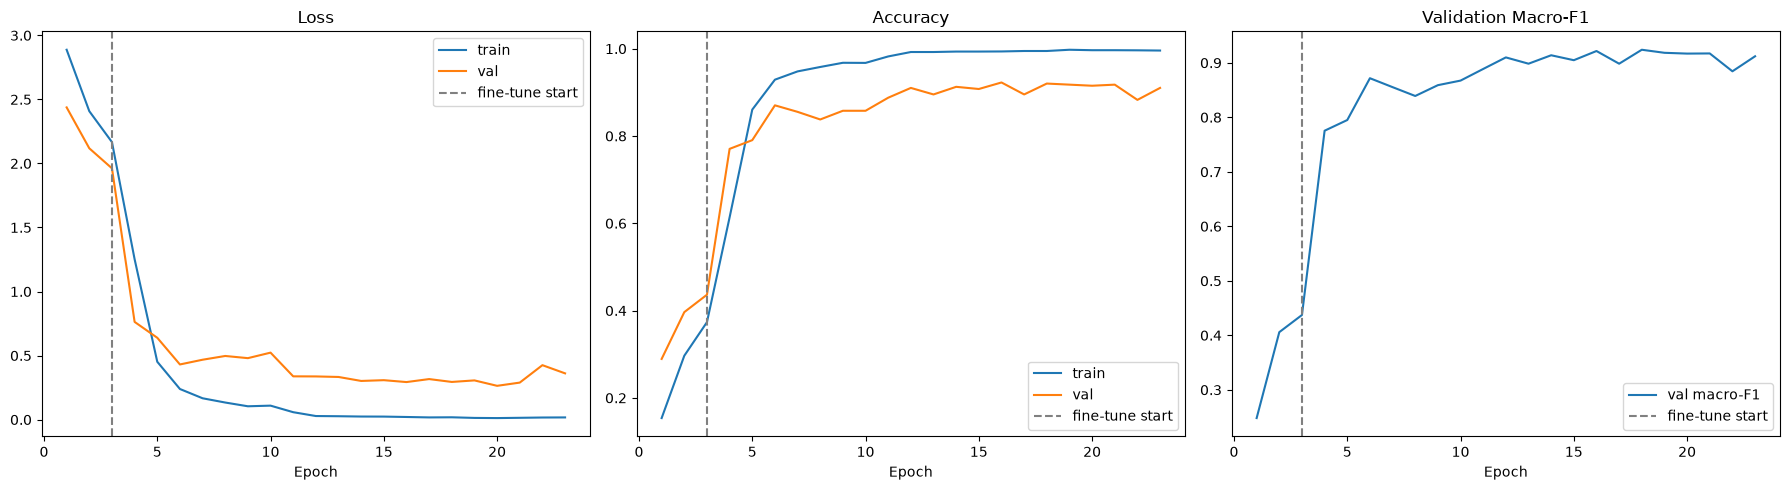

Best stage: finetune
Best epoch: 15
Best val macro-F1: 0.9239589699657972
Best val accuracy: 0.9201995012468828
Checkpoint: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training/best_resnet34_E2.pth


In [6]:
history = {
    'stage': [],
    'epoch': [],
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': [],
    'val_balanced_acc': [],
    'val_f1_macro': [],
    'val_precision_macro': [],
    'val_recall_macro': [],
    'val_f1_weighted': [],
    'learning_rate': []
}

best_val_f1 = -1.0
best_val_acc = -1.0
best_val_loss = float('inf')
best_epoch = 0
best_stage = 'none'
epochs_no_improve = 0

def is_better(f1, acc, loss):
    if f1 > best_val_f1:
        return True
    if abs(f1 - best_val_f1) <= 1e-6 and acc > best_val_acc:
        return True
    if abs(f1 - best_val_f1) <= 1e-6 and abs(acc - best_val_acc) <= 1e-6 and loss < best_val_loss:
        return True
    return False

print('Stage 1: Head warmup')
for epoch in range(1, HEAD_EPOCHS + 1):
    train_loss, train_acc = train_one_epoch(
        model=model,
        loader=train_loader,
        criterion=criterion,
        optimizer=head_optimizer,
        scaler=scaler,
        device=DEVICE,
        use_amp=USE_AMP,
        head_warmup=True
    )
    val_metrics = evaluate(model, val_loader, criterion, DEVICE, USE_AMP)
    lr = head_optimizer.param_groups[-1]['lr']

    history['stage'].append('head')
    history['epoch'].append(epoch)
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_metrics['loss'])
    history['val_acc'].append(val_metrics['accuracy'])
    history['val_balanced_acc'].append(val_metrics['balanced_accuracy'])
    history['val_f1_macro'].append(val_metrics['f1_macro'])
    history['val_precision_macro'].append(val_metrics['precision_macro'])
    history['val_recall_macro'].append(val_metrics['recall_macro'])
    history['val_f1_weighted'].append(val_metrics['f1_weighted'])
    history['learning_rate'].append(lr)

    head_vl = val_metrics['loss']
    head_va = val_metrics['accuracy']
    head_vf = val_metrics['f1_macro']
    print(f'HEAD {epoch}/{HEAD_EPOCHS} | train_loss={train_loss:.4f} | train_acc={train_acc:.4f} | val_loss={head_vl:.4f} | val_acc={head_va:.4f} | val_f1={head_vf:.4f}')

    if is_better(val_metrics['f1_macro'], val_metrics['accuracy'], val_metrics['loss']):
        best_val_f1 = val_metrics['f1_macro']
        best_val_acc = val_metrics['accuracy']
        best_val_loss = val_metrics['loss']
        best_epoch = epoch
        best_stage = 'head'
        save_checkpoint(model, head_optimizer, epoch, 'head', val_metrics)
        print('Checkpoint saved (head).')

print('Stage 2: Full fine-tuning')
for param in model.parameters():
    param.requires_grad = True

backbone_params = [p for n, p in model.named_parameters() if not n.startswith('fc') and p.requires_grad]
head_params = list(model.fc.parameters())

finetune_optimizer = optim.AdamW(
    [
        {'params': backbone_params, 'lr': BACKBONE_LR},
        {'params': head_params, 'lr': HEAD_LR}
    ],
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    finetune_optimizer,
    mode='max',
    factor=LR_FACTOR,
    patience=LR_PATIENCE
)

for epoch in range(1, FINETUNE_EPOCHS + 1):
    train_loss, train_acc = train_one_epoch(
        model=model,
        loader=train_loader,
        criterion=criterion,
        optimizer=finetune_optimizer,
        scaler=scaler,
        device=DEVICE,
        use_amp=USE_AMP,
        head_warmup=False
    )
    val_metrics = evaluate(model, val_loader, criterion, DEVICE, USE_AMP)
    scheduler.step(val_metrics['f1_macro'])
    lr = finetune_optimizer.param_groups[0]['lr']

    history['stage'].append('finetune')
    history['epoch'].append(epoch)
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_metrics['loss'])
    history['val_acc'].append(val_metrics['accuracy'])
    history['val_balanced_acc'].append(val_metrics['balanced_accuracy'])
    history['val_f1_macro'].append(val_metrics['f1_macro'])
    history['val_precision_macro'].append(val_metrics['precision_macro'])
    history['val_recall_macro'].append(val_metrics['recall_macro'])
    history['val_f1_weighted'].append(val_metrics['f1_weighted'])
    history['learning_rate'].append(lr)

    ft_vl = val_metrics['loss']
    ft_va = val_metrics['accuracy']
    ft_vf = val_metrics['f1_macro']
    print(f'FT {epoch}/{FINETUNE_EPOCHS} | train_loss={train_loss:.4f} | train_acc={train_acc:.4f} | val_loss={ft_vl:.4f} | val_acc={ft_va:.4f} | val_f1={ft_vf:.4f} | lr={lr:.2e}')

    if is_better(val_metrics['f1_macro'], val_metrics['accuracy'], val_metrics['loss']):
        best_val_f1 = val_metrics['f1_macro']
        best_val_acc = val_metrics['accuracy']
        best_val_loss = val_metrics['loss']
        best_epoch = epoch
        best_stage = 'finetune'
        epochs_no_improve = 0
        save_checkpoint(model, finetune_optimizer, epoch, 'finetune', val_metrics)
        print('Checkpoint saved (fine-tune).')
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= EARLY_STOPPING_PATIENCE:
            print(f'Early stopping at fine-tune epoch {epoch}.')
            break

history_df = pd.DataFrame(history)
history_df.to_csv(HISTORY_PATH, index=False)
print('History saved:', HISTORY_PATH)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
x = np.arange(1, len(history_df) + 1)

axes[0].plot(x, history_df['train_loss'], label='train')
axes[0].plot(x, history_df['val_loss'], label='val')
axes[0].axvline(HEAD_EPOCHS, color='gray', linestyle='--', label='fine-tune start')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(x, history_df['train_acc'], label='train')
axes[1].plot(x, history_df['val_acc'], label='val')
axes[1].axvline(HEAD_EPOCHS, color='gray', linestyle='--', label='fine-tune start')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].legend()

axes[2].plot(x, history_df['val_f1_macro'], label='val macro-F1')
axes[2].axvline(HEAD_EPOCHS, color='gray', linestyle='--', label='fine-tune start')
axes[2].set_title('Validation Macro-F1')
axes[2].set_xlabel('Epoch')
axes[2].legend()

plt.tight_layout()
plt.savefig(LEARNING_CURVES_PATH, dpi=150)
plt.show()

print('Best stage:', best_stage)
print('Best epoch:', best_epoch)
print('Best val macro-F1:', best_val_f1)
print('Best val accuracy:', best_val_acc)
print('Checkpoint:', CKPT_PATH)


In [7]:
checkpoint = load_checkpoint(CKPT_PATH, DEVICE)
model.load_state_dict(checkpoint['model_state_dict'])

print('Loaded best checkpoint')
print('Stage:', checkpoint.get('stage', 'unknown'))
print('Epoch:', checkpoint.get('epoch', 'unknown'))

test_metrics = evaluate(model, test_loader, criterion, DEVICE, USE_AMP)
test_preds = test_metrics['predictions']
test_labels = test_metrics['labels']

test_loss = test_metrics['loss']
test_acc = test_metrics['accuracy']
test_precision = test_metrics['precision_macro']
test_recall = test_metrics['recall_macro']
test_f1 = test_metrics['f1_macro']
test_balanced_acc = test_metrics['balanced_accuracy']

print('======================================================================')
print('E2 FINAL TEST RESULTS - ResNet-34')
print('======================================================================')
print('Test loss          :', round(float(test_loss), 4))
print('Test accuracy      :', round(float(test_acc), 4))
print('Test precision macro:', round(float(test_precision), 4))
print('Test recall macro  :', round(float(test_recall), 4))
print('Test macro-F1      :', round(float(test_f1), 4))
print('Test balanced acc  :', round(float(test_balanced_acc), 4))

config = {
    'experiment': EXPERIMENT_ID,
    'model': MODEL_NAME,
    'device': str(DEVICE),
    'seed': SEED,
    'dataset': {
        'train_dir': str(TRAIN_DIR),
        'val_dir': str(VAL_DIR),
        'test_dir': str(TEST_DIR),
        'num_classes': EXPECTED_NUM_CLASSES,
        'train_images': len(train_dataset),
        'val_images': len(val_dataset),
        'test_images': len(test_dataset)
    },
    'training': {
        'batch_size': BATCH_SIZE,
        'head_epochs': HEAD_EPOCHS,
        'finetune_epochs': FINETUNE_EPOCHS,
        'head_lr': HEAD_LR,
        'backbone_lr': BACKBONE_LR,
        'weight_decay': WEIGHT_DECAY,
        'lr_factor': LR_FACTOR,
        'lr_patience': LR_PATIENCE,
        'early_stopping_patience': EARLY_STOPPING_PATIENCE,
        'loss': 'CrossEntropyLoss',
        'optimizer': 'AdamW',
        'amp': USE_AMP
    },
    'best_validation': {
        'stage': best_stage,
        'epoch': best_epoch,
        'f1_macro': float(best_val_f1),
        'accuracy': float(best_val_acc),
        'loss': float(best_val_loss)
    },
    'test': {
        'loss': float(test_loss),
        'accuracy': float(test_acc),
        'precision_macro': float(test_precision),
        'recall_macro': float(test_recall),
        'f1_macro': float(test_f1),
        'balanced_accuracy': float(test_balanced_acc)
    },
    'class_names': class_names
}

with open(CONFIG_PATH, 'w') as f:
    json.dump(config, f, indent=2)

print('Config saved:', CONFIG_PATH)


Loaded best checkpoint
Stage: finetune
Epoch: 15
E2 FINAL TEST RESULTS - ResNet-34
Test loss          : 0.4686
Test accuracy      : 0.8741
Test precision macro: 0.8966
Test recall macro  : 0.887
Test macro-F1      : 0.8873
Test balanced acc  : 0.887
Config saved: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training/resnet34_E2_config.json



E2 - ResNet-34 - Top-k Test Accuracy
--------------------------------------
Top- 1: 0.8741
Top- 2: 0.9284
Top- 3: 0.9531
Top- 4: 0.9531
Top- 5: 0.9556
Top- 6: 0.9630
Top- 7: 0.9679
Top- 8: 0.9704
Top- 9: 0.9728
Top-10: 0.9728
Saved: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training/resnet34_E2_topk.json

 ARCHITECTURE COMPARISON: ResNet-18 vs ResNet-34
experiment    model  val_f1_macro  val_accuracy  test_accuracy  test_precision_macro  test_recall_macro  test_f1_macro  test_balanced_accuracy
        E1 resnet18      0.933604      0.932668       0.832099              0.881950           0.848400       0.844915                0.848400
        E2 resnet34      0.923959      0.920200       0.874074              0.896605           0.887048       0.887344                0.887048
Saved: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training/E2_architecture_comparison_resnet18_vs_resnet34.csv


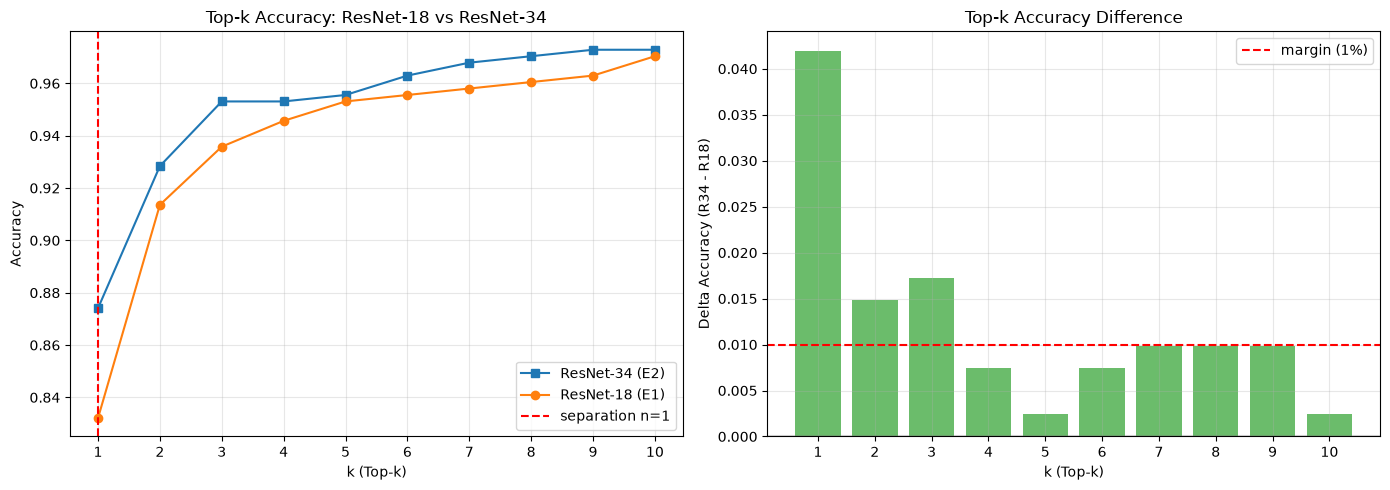


Separation margin: 1%
Separation point: n = 1
 From Top-1 onward, ResNet-34 exceeds ResNet-18 by >= 1%.
Plot saved: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training/E2_topk_comparison_resnet18_vs_resnet34.png
Separation analysis saved: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training/E2_topk_separation_resnet34.json


In [8]:
k_values = list(range(1, 11))
topk_acc = compute_topk(model, test_loader, DEVICE, USE_AMP, k_values)

print('')
print('E2 - ResNet-34 - Top-k Test Accuracy')
print('-' * 38)
for k in k_values:
    print(f'Top-{k:2d}: {topk_acc[k]:.4f}')

topk_payload = {
    'experiment': EXPERIMENT_ID,
    'model': MODEL_NAME,
    'k_values': k_values,
    'top_k_accuracy': {str(k): float(topk_acc[k]) for k in k_values}
}

with open(TOPK_PATH, 'w') as f:
    json.dump(topk_payload, f, indent=2)

print('Saved:', TOPK_PATH)

e1_row = None
results_input = pd.DataFrame()

if RESULTS_PATH.exists():
    results_input = pd.read_csv(RESULTS_PATH)
    e1_rows = results_input[results_input['experiment'] == 'E1']
    if len(e1_rows) > 0:
        if 'val_f1_macro' in e1_rows.columns:
            e1_row = e1_rows.sort_values('val_f1_macro', ascending=False).iloc[0]
        else:
            e1_row = e1_rows.iloc[0]
    else:
        print('WARNING: E1 row not found in experiment_results.csv.')
else:
    print('WARNING: experiment_results.csv not found. Run E1 first.')

e2_row = {
    'experiment': EXPERIMENT_ID,
    'model': MODEL_NAME,
    'val_f1_macro': float(best_val_f1),
    'val_accuracy': float(best_val_acc),
    'test_accuracy': float(test_acc),
    'test_precision_macro': float(test_precision),
    'test_recall_macro': float(test_recall),
    'test_f1_macro': float(test_f1),
    'test_balanced_accuracy': float(test_balanced_acc)
}

if e1_row is not None:
    e1_display = {
        'experiment': 'E1',
        'model': 'resnet18',
        'val_f1_macro': e1_row.get('val_f1_macro', np.nan),
        'val_accuracy': e1_row.get('val_accuracy', np.nan),
        'test_accuracy': e1_row.get('test_accuracy', np.nan),
        'test_precision_macro': e1_row.get('test_precision_macro', np.nan),
        'test_recall_macro': e1_row.get('test_recall_macro', np.nan),
        'test_f1_macro': e1_row.get('test_f1_macro', np.nan),
        'test_balanced_accuracy': e1_row.get('test_balanced_accuracy', np.nan)
    }
    comparison_df = pd.DataFrame([e1_display, e2_row])
else:
    comparison_df = pd.DataFrame([e2_row])

comparison_df.to_csv(COMPARISON_PATH, index=False)

print('')
print('======================================================================')
print(' ARCHITECTURE COMPARISON: ResNet-18 vs ResNet-34')
print('======================================================================')
print(comparison_df.to_string(index=False))
print('Saved:', COMPARISON_PATH)

ks = list(range(1, 11))
resnet34_accs = [float(topk_acc[k]) for k in ks]
resnet18_accs = None
diff = None
separation_k = None

if E1_TOPK_PATH.exists():
    with open(E1_TOPK_PATH, 'r') as f:
        e1_topk = json.load(f)
    resnet18_accs = [float(e1_topk['top_k_accuracy'][str(k)]) for k in ks]
    diff = [r - e for r, e in zip(resnet34_accs, resnet18_accs)]
    separation_k = next((k for k, d in zip(ks, diff) if d >= 0.01), None)
else:
    print('WARNING: E1 Top-k file not found:', E1_TOPK_PATH)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(ks, resnet34_accs, 's-', label='ResNet-34 (E2)')
if resnet18_accs is not None:
    axes[0].plot(ks, resnet18_accs, 'o-', label='ResNet-18 (E1)')
if separation_k is not None:
    axes[0].axvline(separation_k, color='red', linestyle='--', label=f'separation n={separation_k}')
axes[0].set_xlabel('k (Top-k)')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Top-k Accuracy: ResNet-18 vs ResNet-34')
axes[0].set_xticks(ks)
axes[0].legend()
axes[0].grid(alpha=0.3)

if diff is not None:
    axes[1].bar(ks, diff, color='tab:green', alpha=0.7)
    axes[1].axhline(0.01, color='red', linestyle='--', label='margin (1%)')
    axes[1].axhline(0.0, color='gray', linestyle='-', alpha=0.3)
    axes[1].set_xlabel('k (Top-k)')
    axes[1].set_ylabel('Delta Accuracy (R34 - R18)')
    axes[1].set_title('Top-k Accuracy Difference')
    axes[1].set_xticks(ks)
    axes[1].legend()
    axes[1].grid(alpha=0.3)
else:
    axes[1].text(0.5, 0.5, 'E1 Top-k file not found', ha='center', va='center')
    axes[1].set_axis_off()

plt.tight_layout()
plt.savefig(TOPK_PLOT_PATH, dpi=150, bbox_inches='tight')
plt.show()

print('')
print('Separation margin: 1%')
if separation_k is not None:
    print('Separation point: n =', separation_k)
    print(' From Top-' + str(separation_k) + ' onward, ResNet-34 exceeds ResNet-18 by >= 1%.')
else:
    print('No clear separation point found.')
print('Plot saved:', TOPK_PLOT_PATH)

sep_payload = {
    'separation_margin': 0.01,
    'separation_k': separation_k,
    'k_values': ks,
    'resnet18_topk': {str(k): float(a) for k, a in zip(ks, resnet18_accs)} if resnet18_accs is not None else None,
    'resnet34_topk': {str(k): float(a) for k, a in zip(ks, resnet34_accs)},
    'difference': {str(k): float(d) for k, d in zip(ks, diff)} if diff is not None else None
}

with open(SEPARATION_PATH, 'w') as f:
    json.dump(sep_payload, f, indent=2)

print('Separation analysis saved:', SEPARATION_PATH)


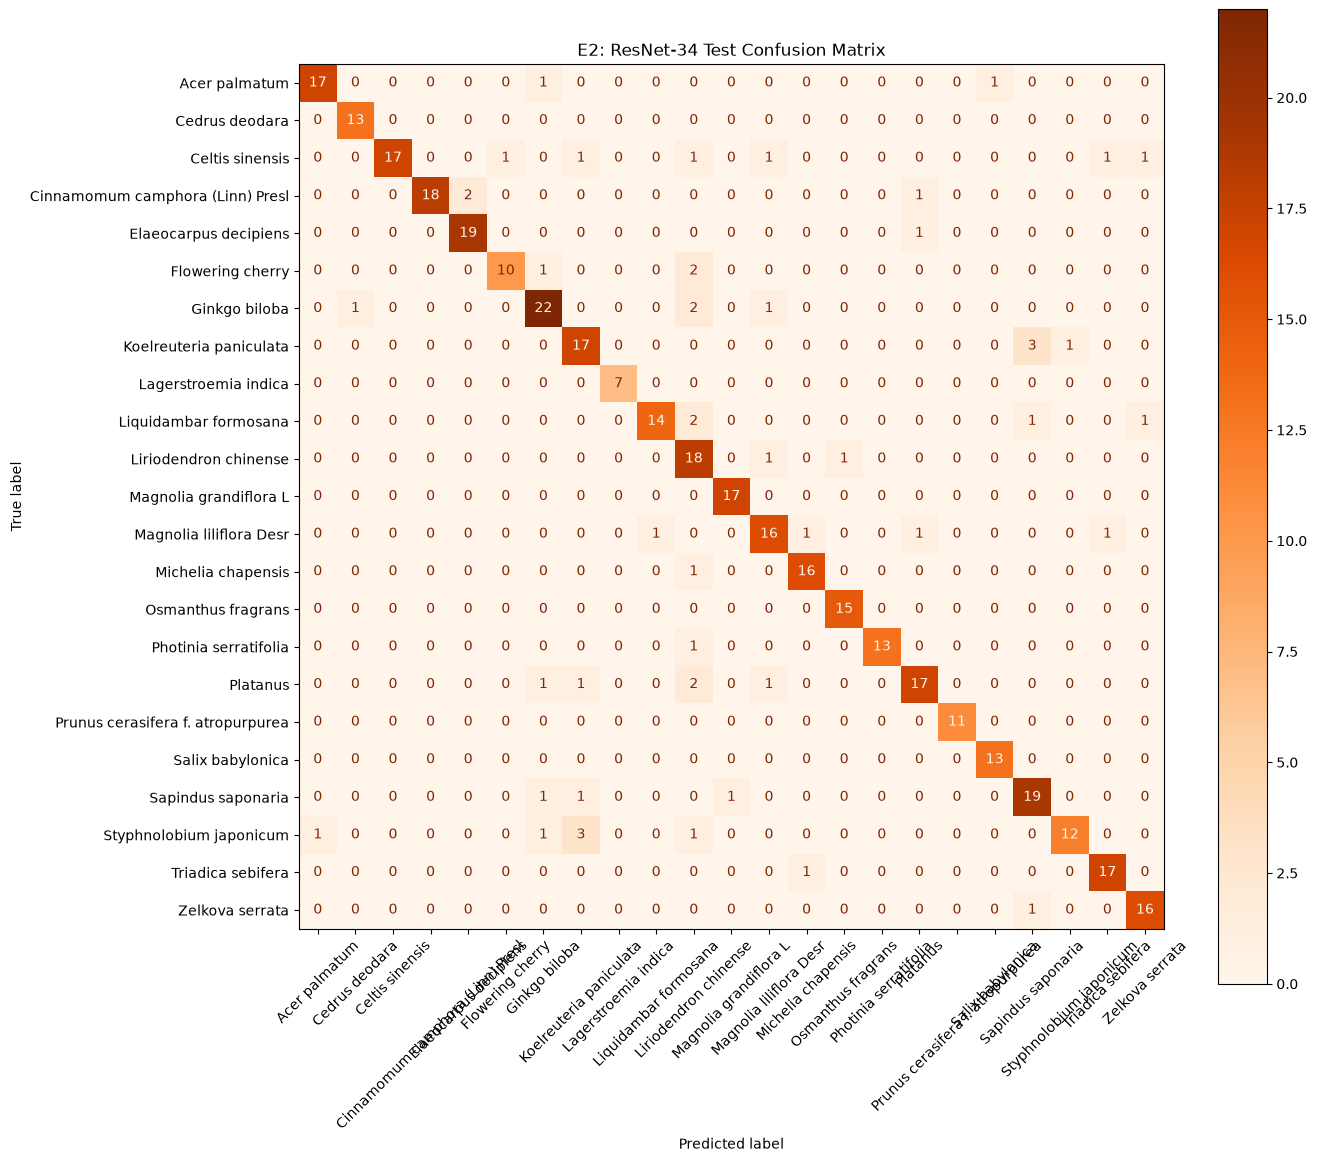

Confusion matrix saved: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training/resnet34_E2_confusion_matrix.csv

E2: ResNet-34 - Per-class metrics sorted by F1
                            class  precision   recall  f1-score  support
Prunus cerasifera f. atropurpurea   1.000000 1.000000  1.000000     11.0
             Lagerstroemia indica   1.000000 1.000000  1.000000      7.0
           Magnolia grandiflora L   0.944444 1.000000  0.971429     17.0
               Osmanthus fragrans   0.937500 1.000000  0.967742     15.0
                   Cedrus deodara   0.928571 1.000000  0.962963     13.0
                 Salix babylonica   0.928571 1.000000  0.962963     13.0
            Photinia serratifolia   1.000000 0.928571  0.962963     14.0
            Elaeocarpus decipiens   0.904762 0.950000  0.926829     20.0
 Cinnamomum camphora (Linn) Presl   1.000000 0.857143  0.923077     21.0
                Triadica sebifera   0.894737 0.944444  0.918919     

In [9]:
cm = confusion_matrix(test_labels, test_preds, labels=np.arange(len(class_names)))

fig, ax = plt.subplots(figsize=(14, 12))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=45, values_format='d', cmap='Oranges')
plt.title('E2: ResNet-34 Test Confusion Matrix')
plt.tight_layout()
plt.savefig(CONFUSION_PNG_PATH, dpi=150)
plt.show()

pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(CONFUSION_CSV_PATH)
print('Confusion matrix saved:', CONFUSION_CSV_PATH)

report = classification_report(
    test_labels,
    test_preds,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

per_class_rows = []
for cls in class_names:
    if cls in report:
        per_class_rows.append({
            'class': cls,
            'precision': report[cls]['precision'],
            'recall': report[cls]['recall'],
            'f1-score': report[cls]['f1-score'],
            'support': report[cls]['support']
        })

per_class_df = pd.DataFrame(per_class_rows).sort_values('f1-score', ascending=False)
per_class_df.to_csv(PERCLASS_CSV_PATH, index=False)

print('')
print('E2: ResNet-34 - Per-class metrics sorted by F1')
print(per_class_df.to_string(index=False))
print('Per-class metrics saved:', PERCLASS_CSV_PATH)

report_lines = [
    '======================================================================',
    'E2 REPORT - ResNet-34',
    '======================================================================',
    '',
    'Dataset',
    ' Train : ' + str(len(train_dataset)),
    ' Val   : ' + str(len(val_dataset)),
    ' Test  : ' + str(len(test_dataset)),
    '',
    'Best validation',
    ' Stage       : ' + str(best_stage),
    ' Epoch       : ' + str(best_epoch),
    ' Macro-F1    : ' + str(round(float(best_val_f1), 4)),
    ' Accuracy    : ' + str(round(float(best_val_acc), 4)),
    ' Loss        : ' + str(round(float(best_val_loss), 4)),
    '',
    'Final test results',
    ' Loss              : ' + str(round(float(test_loss), 4)),
    ' Accuracy          : ' + str(round(float(test_acc), 4)),
    ' Precision macro   : ' + str(round(float(test_precision), 4)),
    ' Recall macro      : ' + str(round(float(test_recall), 4)),
    ' Macro-F1          : ' + str(round(float(test_f1), 4)),
    ' Balanced accuracy : ' + str(round(float(test_balanced_acc), 4)),
    '',
    'Saved artifacts',
    ' Checkpoint       : ' + str(CKPT_PATH),
    ' Config           : ' + str(CONFIG_PATH),
    ' History          : ' + str(HISTORY_PATH),
    ' Learning curves  : ' + str(LEARNING_CURVES_PATH),
    ' Top-k JSON       : ' + str(TOPK_PATH),
    ' Comparison CSV   : ' + str(COMPARISON_PATH),
    ' Top-k plot       : ' + str(TOPK_PLOT_PATH),
    ' Separation JSON  : ' + str(SEPARATION_PATH),
    ' Confusion PNG    : ' + str(CONFUSION_PNG_PATH),
    ' Confusion CSV    : ' + str(CONFUSION_CSV_PATH),
    ' Per-class CSV    : ' + str(PERCLASS_CSV_PATH),
    ' Registry         : ' + str(RESULTS_PATH)
]

newline = chr(10)
with open(REPORT_PATH, 'w') as f:
    f.write(newline.join(report_lines))

print('Report saved:', REPORT_PATH)

result_row = {
    'experiment': EXPERIMENT_ID,
    'model': MODEL_NAME,
    'augmentation': 'baseline_mild',
    'loss': 'CrossEntropyLoss',
    'optimizer': 'AdamW',
    'val_f1_macro': float(best_val_f1),
    'val_accuracy': float(best_val_acc),
    'val_loss': float(best_val_loss),
    'test_accuracy': float(test_acc),
    'test_precision_macro': float(test_precision),
    'test_recall_macro': float(test_recall),
    'test_f1_macro': float(test_f1),
    'test_balanced_accuracy': float(test_balanced_acc),
    'test_top5': float(topk_acc.get(5, np.nan)),
    'improvement': 'architecture_resnet34',
    'base_experiment': 'E1'
}

if RESULTS_PATH.exists():
    results_df = pd.read_csv(RESULTS_PATH)
    if 'experiment' in results_df.columns and 'model' in results_df.columns:
        results_df = results_df[~((results_df['experiment'] == EXPERIMENT_ID) & (results_df['model'] == MODEL_NAME))]
    results_df = pd.concat([results_df, pd.DataFrame([result_row])], ignore_index=True)
else:
    results_df = pd.DataFrame([result_row])

results_df.to_csv(RESULTS_PATH, index=False)
print('Experiment registry updated:', RESULTS_PATH)
print(results_df.to_string(index=False))

print('')
print('RESNET-34 TRAINING COMPLETE')
print('Checkpoint :', CKPT_PATH)
print('Registry   :', RESULTS_PATH)
print('Top-k JSON :', TOPK_PATH)
print('Comparison :', COMPARISON_PATH)
